In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("crop_suitability.csv")

df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


## 3. Understanding the Dataset

Before performing analysis and model training, we need to understand the structure of the dataset.

We will check:
- Number of rows and columns
- Names of the features
- Data types of each column
- Number of non-null values
- Approximate memory usage

This helps us identify whether the dataset contains missing values, incorrect data types, or other data-quality issues.

In [3]:
df.shape

(3130, 8)

In [4]:
df.columns

Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3130 entries, 0 to 3129
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            3130 non-null   int64  
 1   P            3130 non-null   int64  
 2   K            3130 non-null   int64  
 3   temperature  3130 non-null   float64
 4   humidity     3130 non-null   float64
 5   ph           3130 non-null   float64
 6   rainfall     3130 non-null   float64
 7   label        3130 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 195.8+ KB


## 4. Data Quality Check

We check for missing values and duplicate records to ensure the dataset is clean before model training.

In [6]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Duplicate rows: 0


## 5. Statistical Summary

We use descriptive statistics to understand the distribution and range of the numerical features.

In [8]:
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,3130.000000,3130.000000,3130.000000,3130.000000,3130.000000,3130.000000,3130.000000
mean,48.899681,54.889457,47.262620,25.292559,67.398103,6.481364,100.489818
std,36.328279,31.408645,49.509083,5.037349,24.499530,0.850018,54.116112
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,5.314507
25%,21.000000,35.000000,20.000000,22.179319,52.821016,5.927894,63.502503
50%,36.000000,54.000000,30.000000,25.400592,77.679536,6.418898,91.638957
75%,83.000000,69.000000,49.000000,28.430888,86.899341,6.962386,120.586041
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


## 6. Target Class Distribution

We examine the distribution of crop labels to understand how many samples are available for each crop.

In [9]:
df['label'].value_counts()

label
rice           176
maize          149
banana         145
coffee         144
apple          134
watermelon     134
mango          130
orange         130
cotton         130
Soyabeans      130
grapes         128
mungbean       100
coconut        100
papaya         100
muskmelon      100
pomegranate    100
lentil         100
blackgram      100
mothbeans      100
cowpeas        100
pigeonpeas     100
kidneybeans    100
chickpea       100
beans          100
peas           100
groundnuts     100
jute           100
Name: count, dtype: int64

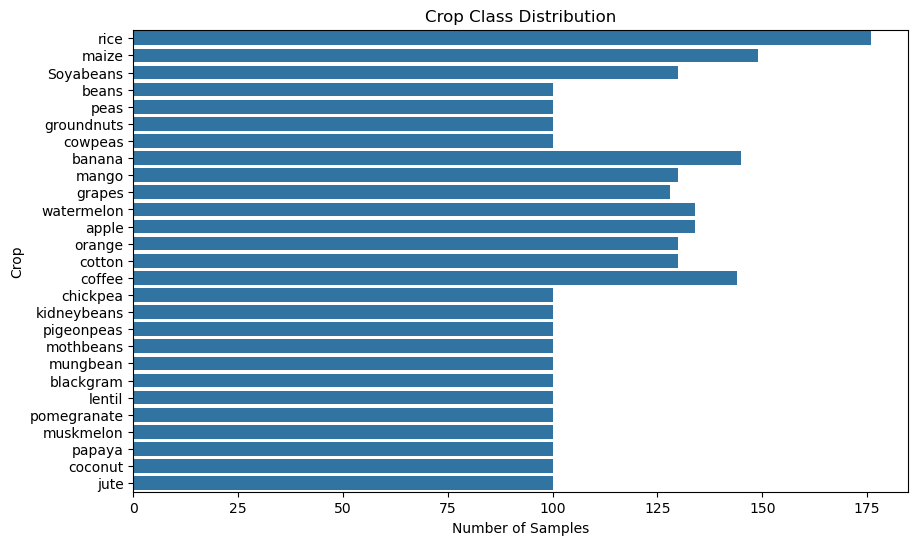

In [10]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, y='label')
plt.title("Crop Class Distribution")
plt.xlabel("Number of Samples")
plt.ylabel("Crop")
plt.show()

## 7. Feature Distributions

Histograms help us understand the distribution and spread of the numerical features in the dataset.

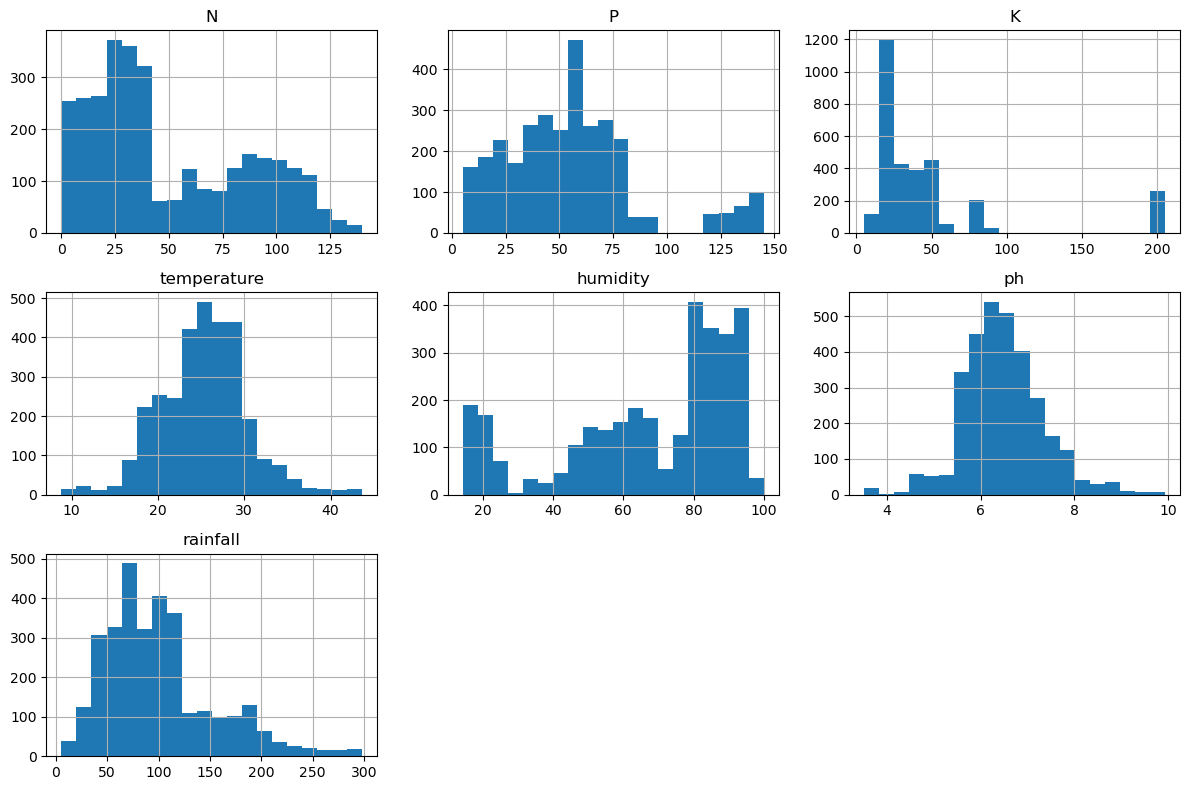

In [11]:
df.hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

### Observation

The features show different distributions and ranges. Temperature and pH are relatively concentrated, while N, P, K, humidity and rainfall show wider or skewed distributions.

## 8. Outlier Detection

Boxplots are used to identify the spread of numerical features and potential outliers.

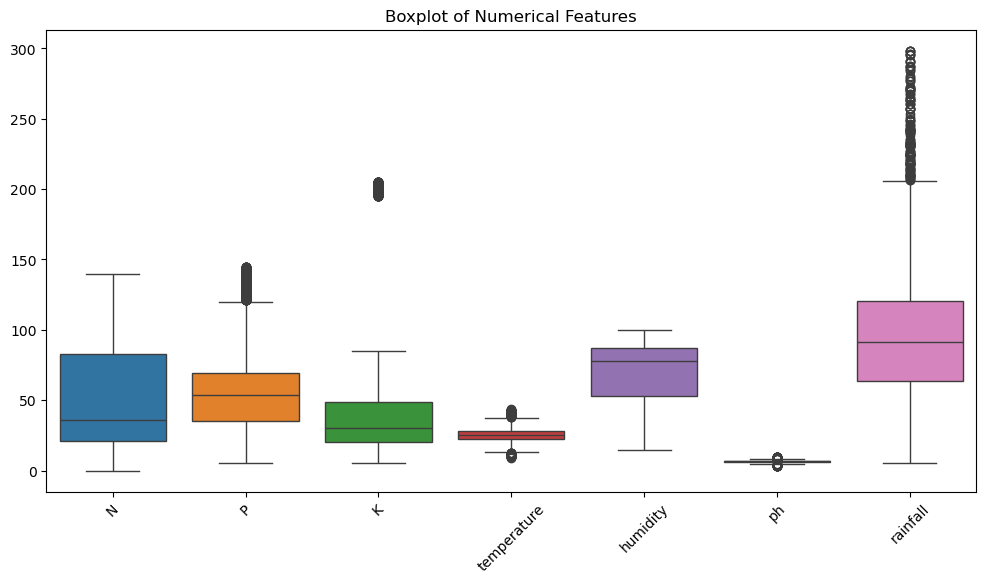

In [12]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df[['N', 'P', 'K', 'temperature',
                     'humidity', 'ph', 'rainfall']])

plt.title("Boxplot of Numerical Features")
plt.xticks(rotation=45)
plt.show()

### Observation

Some features show potential outliers, especially P, K, temperature, pH and rainfall. These values are retained because they may represent valid agricultural conditions.

## 9. Correlation Analysis

The correlation heatmap shows the strength and direction of relationships between numerical features.

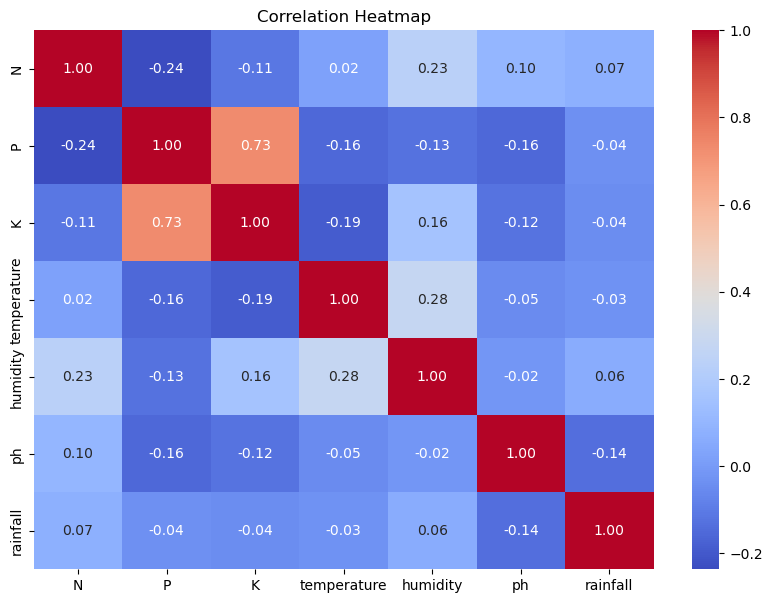

In [13]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.drop(columns='label').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

## 10. Feature Relationships

A pairplot helps visualize relationships between numerical features and shows how different crop classes are distributed.

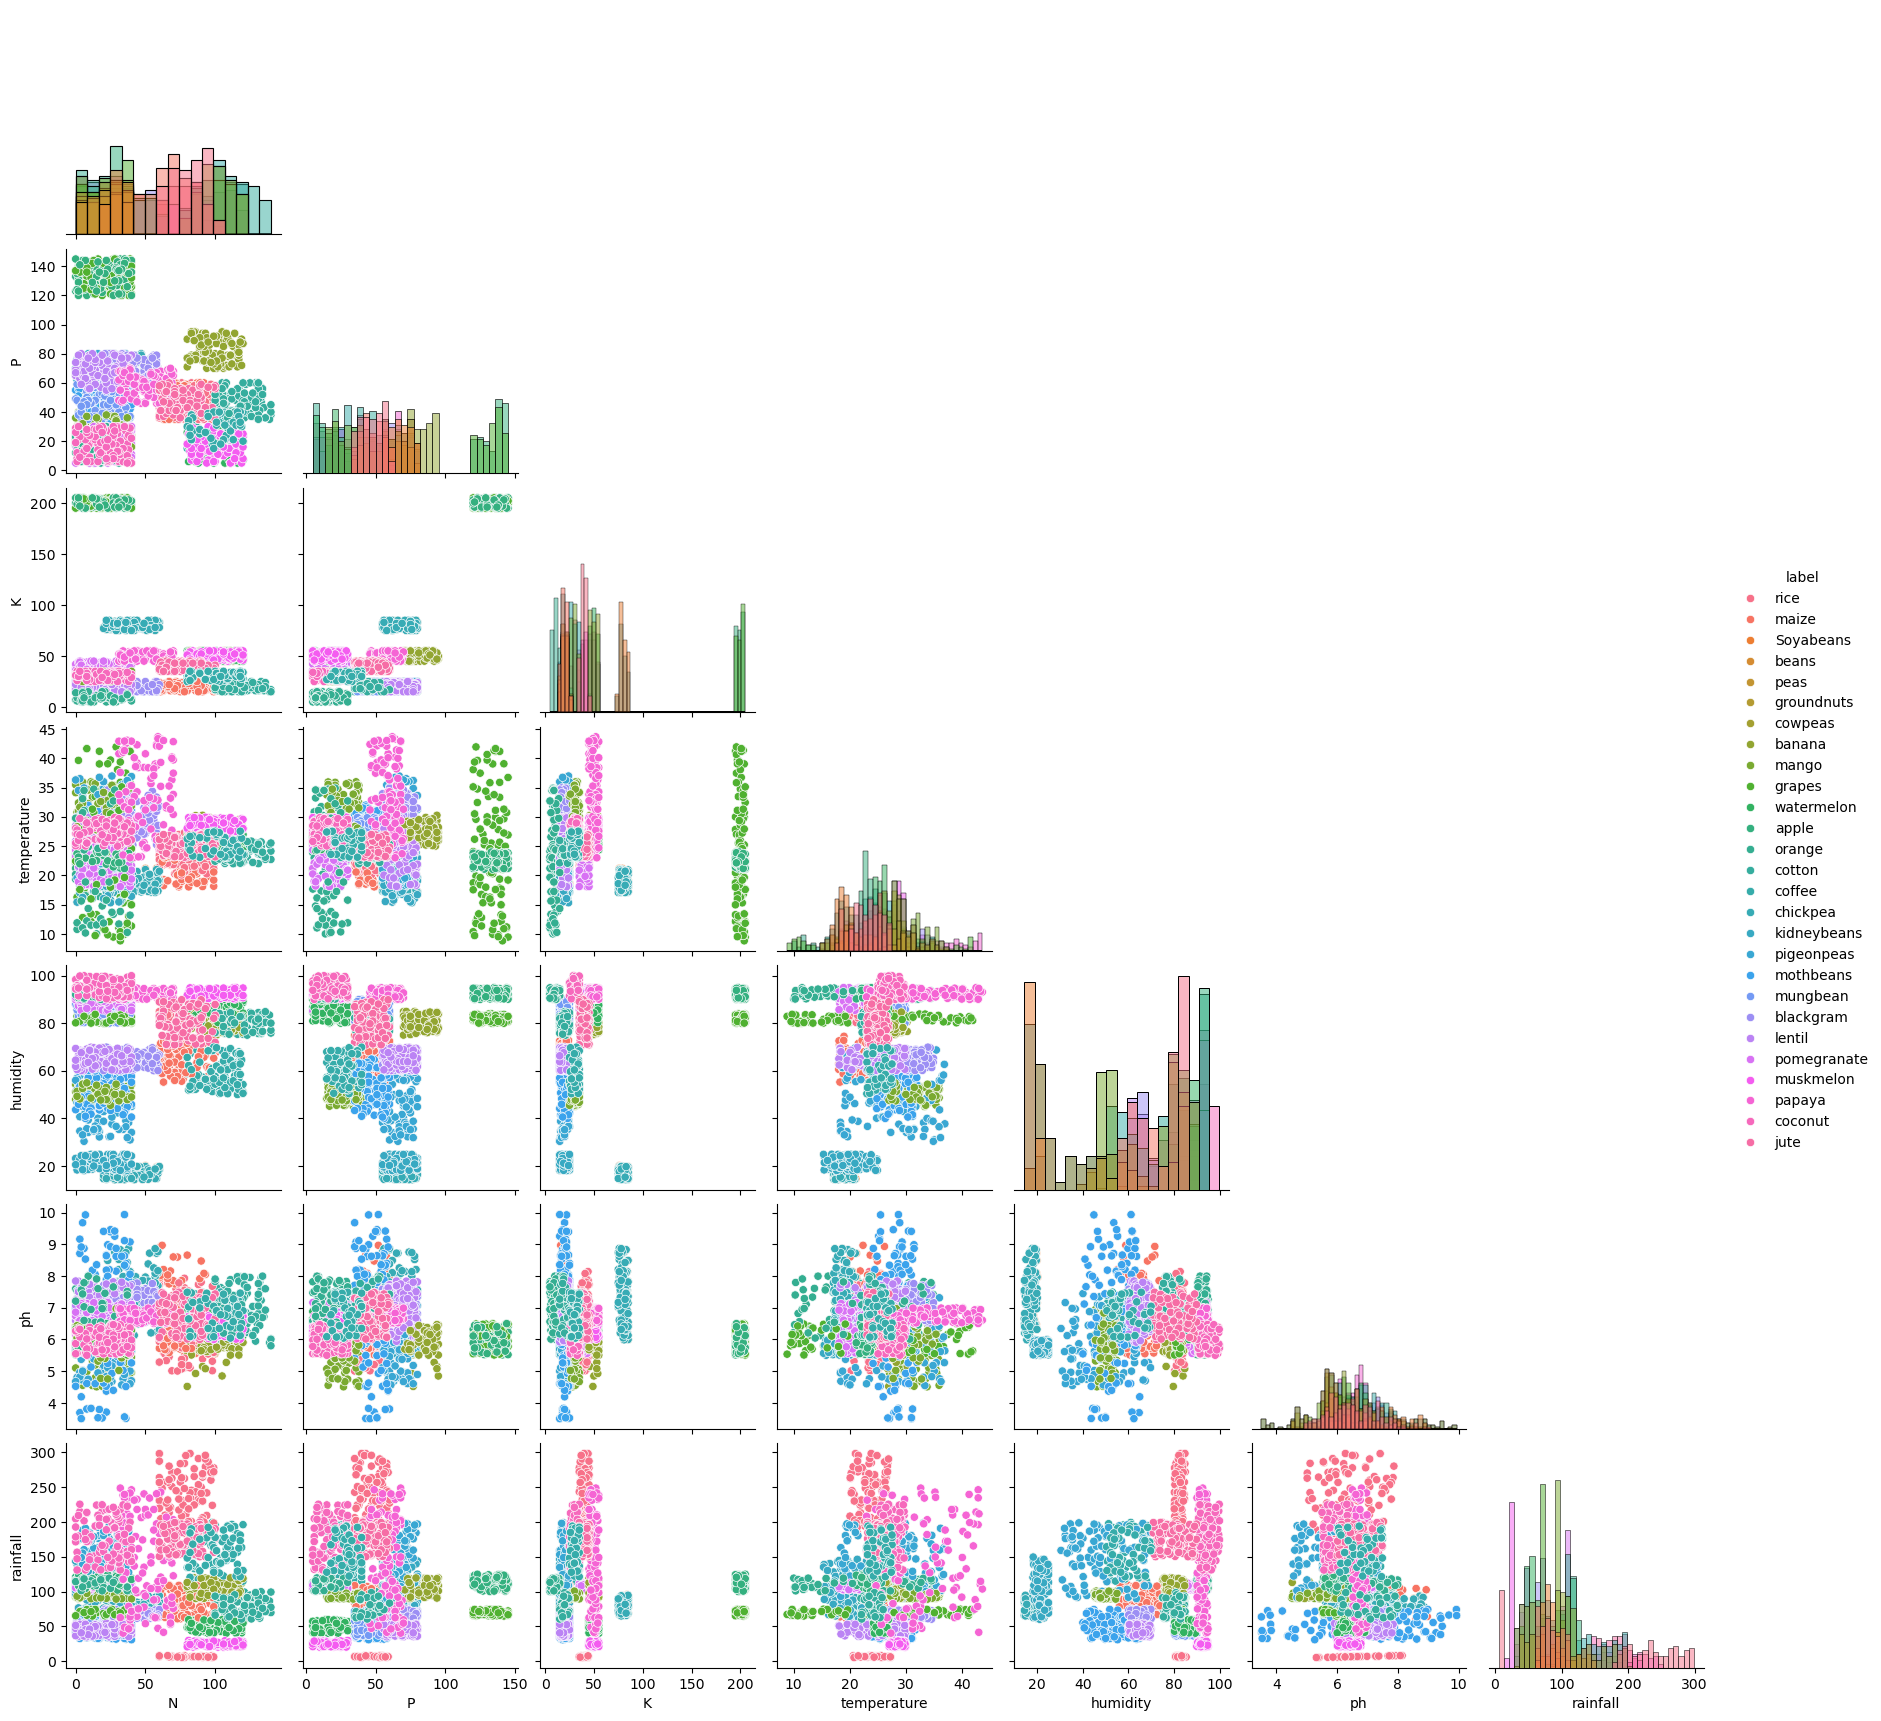

In [15]:
sns.pairplot(
    df,
    hue='label',
    diag_kind='hist',
    corner=True
)

plt.show()

### Observation

The pairplot shows that some crop classes form distinct patterns, while others overlap across the feature space.

## 11. Feature and Target Selection

The soil and environmental parameters are used as input features, while the crop label is the target variable to be predicted.

In [16]:
X = df[['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']]
y = df['label']

print("Features:", X.columns.tolist())
print("Target:", y.name)

Features: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
Target: label


## 12. Train-Test Split

The dataset is divided into training and testing sets. The training set is used to build the models, while the test set is used to evaluate their performance on unseen data.

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (2504, 7)
Testing data: (626, 7)


## 13. Model Building

Five classification algorithms are trained and compared:
- Logistic Regression
- K-Nearest Neighbors (KNN)
- Support Vector Machine (SVM)
- Decision Tree
- Random Forest

Scaling is applied to Logistic Regression, KNN and SVM because these models are sensitive to feature magnitude.

In [18]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000))
    ]),
    
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),
    
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC())
    ]),
    
    "Decision Tree": Pipeline([
        ("model", DecisionTreeClassifier(random_state=42))
    ]),
    
    "Random Forest": Pipeline([
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ])
}

In [19]:
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully")

Logistic Regression trained successfully
KNN trained successfully
SVM trained successfully
Decision Tree trained successfully
Random Forest trained successfully


## 14. Model Evaluation

The trained models are evaluated on the unseen test set using accuracy, precision, recall, and F1-score.

In [21]:
results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, average="weighted", zero_division=0)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,SVM,0.798722,0.780801,0.798722,0.786602
1,Logistic Regression,0.752396,0.743825,0.752396,0.743262
2,KNN,0.736422,0.732364,0.736422,0.733706
3,Random Forest,0.718850,0.718006,0.718850,0.718098
4,Decision Tree,0.717252,0.711104,0.717252,0.713362


## 15. SVM Detailed Evaluation

SVM achieved the best overall performance among the five models. We further evaluate it using a confusion matrix and classification report.

In [22]:
svm_model = models["SVM"]

y_pred_svm = svm_model.predict(X_test)

print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

   Soyabeans       0.57      1.00      0.72        26
       apple       1.00      1.00      1.00        27
      banana       1.00      1.00      1.00        29
       beans       0.40      0.40      0.40        20
   blackgram       1.00      1.00      1.00        20
    chickpea       0.00      0.00      0.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        29
      cotton       1.00      1.00      1.00        26
     cowpeas       0.40      0.50      0.44        20
      grapes       1.00      1.00      1.00        25
  groundnuts       0.26      0.25      0.26        20
        jute       0.87      1.00      0.93        20
 kidneybeans       0.36      0.40      0.38        20
      lentil       1.00      1.00      1.00        20
       maize       1.00      1.00      1.00        30
       mango       1.00      1.00      1.00        26
   mothbeans       0.29    

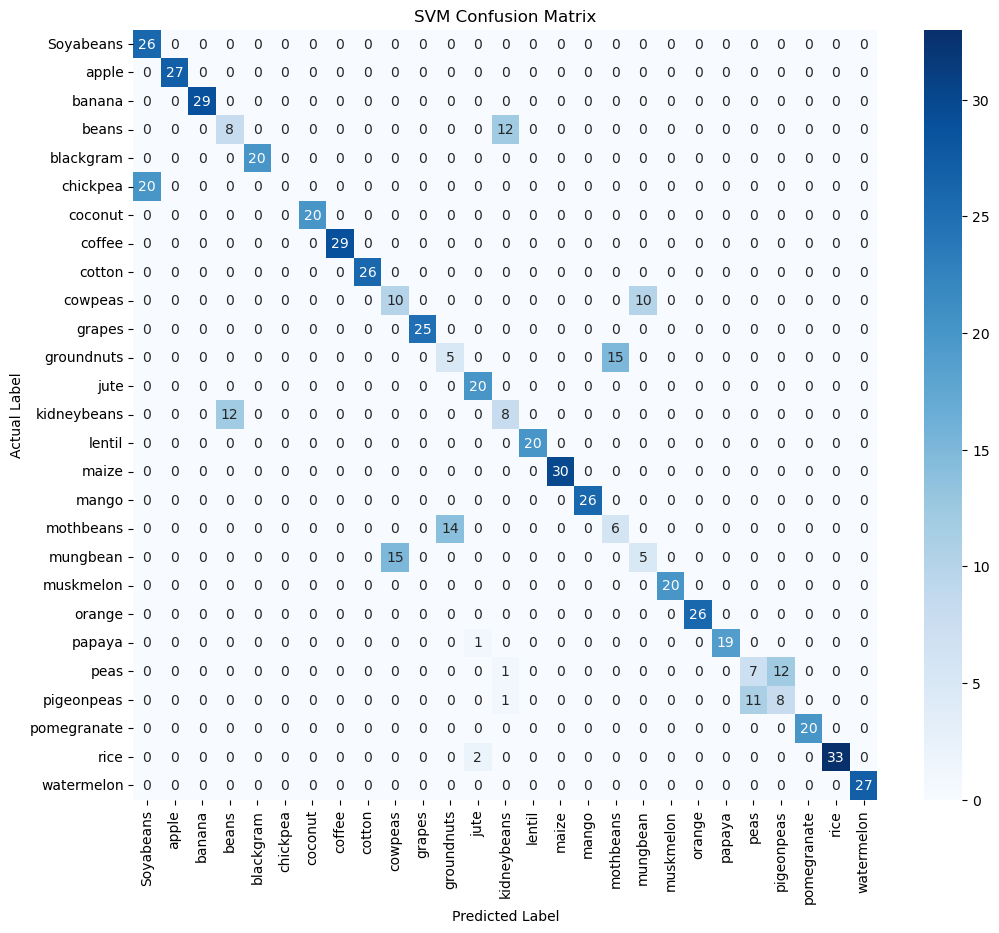

In [23]:
cm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=sorted(y_test.unique()),
    yticklabels=sorted(y_test.unique())
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SVM Confusion Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()

### Observation

The confusion matrix compares the actual crop labels with the crop labels predicted by the SVM model. The rows represent the actual classes, while the columns represent the predicted classes. Therefore, the diagonal elements represent correct predictions, whereas the off-diagonal elements represent misclassifications.

The SVM model performs very well for several crops. For example, Soyabeans (26/26), Apple (27/27), Banana (29/29), Blackgram (20/20), Coconut (20/20), Coffee (29/29), Cotton (26/26), Grapes (25/25), Jute (20/20), Lentil (20/20), Maize (30/30), Mango (26/26), Muskmelon (20/20), Orange (26/26), Pomegranate (20/20), and Watermelon (27/27) are classified correctly for all their test samples.

However, some crop classes show significant misclassification. For example, all 20 Chickpea samples are incorrectly predicted as Soyabeans. Similarly, 12 out of 20 Beans samples are predicted as Groundnuts, while 15 out of 20 Groundnuts samples are predicted as Mothbeans. Mothbeans and Mungbean also show considerable confusion, with 14 Mothbeans samples predicted as Groundnuts and 15 Mungbean samples predicted as Cowpeas.

There is also confusion between Peas and Pigeonpeas. Only 7 out of 20 Peas samples are correctly classified, while 12 are predicted as Pigeonpeas. For Pigeonpeas, 8 out of 20 samples are correctly classified and 11 are predicted as Peas.

These misclassifications indicate that some crop classes have similar combinations of N, P, K, temperature, humidity, pH, and rainfall values. Therefore, the SVM model can distinguish many crops clearly, but it has difficulty separating certain crops with overlapping feature patterns.

Overall, the confusion matrix supports the test-set result of approximately 79.87% accuracy. However, accuracy alone does not provide the complete picture, because the model performs very differently across individual crop classes. Therefore, precision, recall, F1-score and further model tuning should also be considered before selecting the final model.

### Observation

The confusion matrix compares the actual crop labels with the crop labels predicted by the SVM model. The rows represent the actual classes, while the columns represent the predicted classes. Therefore, the diagonal elements represent correct predictions, whereas the off-diagonal elements represent misclassifications.

The SVM model performs very well for several crops. For example, Soyabeans (26/26), Apple (27/27), Banana (29/29), Blackgram (20/20), Coconut (20/20), Coffee (29/29), Cotton (26/26), Grapes (25/25), Jute (20/20), Lentil (20/20), Maize (30/30), Mango (26/26), Muskmelon (20/20), Orange (26/26), Pomegranate (20/20), and Watermelon (27/27) are classified correctly for all their test samples.

However, some crop classes show significant misclassification. For example, all 20 Chickpea samples are incorrectly predicted as Soyabeans. Similarly, 12 out of 20 Beans samples are predicted as Groundnuts, while 15 out of 20 Groundnuts samples are predicted as Mothbeans. Mothbeans and Mungbean also show considerable confusion, with 14 Mothbeans samples predicted as Groundnuts and 15 Mungbean samples predicted as Cowpeas.

There is also confusion between Peas and Pigeonpeas. Only 7 out of 20 Peas samples are correctly classified, while 12 are predicted as Pigeonpeas. For Pigeonpeas, 8 out of 20 samples are correctly classified and 11 are predicted as Peas.

These misclassifications indicate that some crop classes have similar combinations of N, P, K, temperature, humidity, pH, and rainfall values in the dataset. Therefore, the SVM model can distinguish many crops clearly, but it has difficulty separating certain crops with overlapping feature patterns.

Overall, the confusion matrix supports the test-set result of approximately 79.87% accuracy. However, accuracy alone does not provide the complete picture because the model performs differently across individual crop classes. Therefore, precision, recall, F1-score, and further model tuning should also be considered before selecting the final model.

The misclassified classes identified from the confusion matrix will be useful for investigating possible improvements to the model in the next steps.

## 16. Classification Report

The classification report provides precision, recall, and F1-score for each crop class. This helps identify which crops are classified well and which crops require further improvement.

In [24]:
print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

   Soyabeans       0.57      1.00      0.72        26
       apple       1.00      1.00      1.00        27
      banana       1.00      1.00      1.00        29
       beans       0.40      0.40      0.40        20
   blackgram       1.00      1.00      1.00        20
    chickpea       0.00      0.00      0.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        29
      cotton       1.00      1.00      1.00        26
     cowpeas       0.40      0.50      0.44        20
      grapes       1.00      1.00      1.00        25
  groundnuts       0.26      0.25      0.26        20
        jute       0.87      1.00      0.93        20
 kidneybeans       0.36      0.40      0.38        20
      lentil       1.00      1.00      1.00        20
       maize       1.00      1.00      1.00        30
       mango       1.00      1.00      1.00        26
   mothbeans       0.29    

### Observation

The classification report shows that the SVM model performs very well for several crop classes. Classes such as apple, banana, blackgram, coconut, coffee, cotton, grapes, lentil, maize, mango, muskmelon, orange and pomegranate achieve an F1-score of 1.00. Jute, papaya and rice also show strong performance.

However, some classes have much lower performance. Chickpea has an F1-score of 0.00, while groundnuts, mothbeans, mungbean, kidneybeans, peas, beans, pigeonpeas and cowpeas have F1-scores below 0.50. This indicates that the model has difficulty distinguishing these classes.

The overall accuracy is approximately 80% and the weighted F1-score is 0.79. However, the macro F1-score is lower at 0.76, showing that performance is not uniform across all crop classes.

Therefore, although SVM is currently the best-performing model among the five tested models, there is still scope for improvement, particularly for the poorly classified crop classes.

## 17. Cross-Validation

Five-fold cross-validation is used to evaluate the consistency of each model. The weighted F1-score is used because it considers the performance of all crop classes while accounting for their sample sizes.

In [27]:
from sklearn.model_selection import cross_val_score

cv_results = []

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="f1_weighted",
        n_jobs=-1
    )
    
    cv_results.append({
        "Model": name,
        "Mean CV F1": scores.mean(),
        "Std CV F1": scores.std()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    by="Mean CV F1",
    ascending=False
).reset_index(drop=True)

cv_results_df

,Model,Mean CV F1,Std CV F1
0,SVM,0.792724,0.008052
1,Logistic Regression,0.751738,0.010394
2,KNN,0.750783,0.007801
3,Random Forest,0.726797,0.006948
4,Decision Tree,0.722098,0.010088


### Observation

Five-fold cross-validation confirms that SVM is the best-performing model, achieving a mean weighted F1-score of 79.27%. It also shows a low standard deviation of 0.81%, indicating consistent performance across the five folds.

Logistic Regression and KNN perform next with mean F1-scores of 75.17% and 75.08%, respectively. Random Forest and Decision Tree show lower mean F1-scores of 72.68% and 72.21%.

Therefore, SVM remains the strongest candidate for the final model. However, hyperparameter tuning will be performed to check whether its performance can be improved further.

## 18. SVM Hyperparameter Tuning

Grid Search is used to test different SVM hyperparameter combinations and identify the configuration that gives the best cross-validation performance.

In [28]:
from sklearn.model_selection import GridSearchCV

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC())
])

param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__kernel": ["linear", "rbf", "poly"],
    "svm__gamma": ["scale", "auto"]
}

grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1:", grid_search.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters: {'svm__C': 1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Best CV F1: 0.7927244651691974


## 19. Evaluation of Tuned SVM

The best SVM configuration obtained through Grid Search is evaluated on the test set to determine whether tuning improved the model's performance.

In [29]:
best_svm = grid_search.best_estimator_

y_pred_tuned = best_svm.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Test Precision:", precision_score(y_test, y_pred_tuned, average="weighted"))
print("Test Recall:", recall_score(y_test, y_pred_tuned, average="weighted"))
print("Test F1-Score:", f1_score(y_test, y_pred_tuned, average="weighted"))

Test Accuracy: 0.7987220447284346
Test Precision: 0.7808012329839191
Test Recall: 0.7987220447284346
Test F1-Score: 0.7866017629435885


In [30]:
print(classification_report(y_test, y_pred_tuned))

              precision    recall  f1-score   support

   Soyabeans       0.57      1.00      0.72        26
       apple       1.00      1.00      1.00        27
      banana       1.00      1.00      1.00        29
       beans       0.40      0.40      0.40        20
   blackgram       1.00      1.00      1.00        20
    chickpea       0.00      0.00      0.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        29
      cotton       1.00      1.00      1.00        26
     cowpeas       0.40      0.50      0.44        20
      grapes       1.00      1.00      1.00        25
  groundnuts       0.26      0.25      0.26        20
        jute       0.87      1.00      0.93        20
 kidneybeans       0.36      0.40      0.38        20
      lentil       1.00      1.00      1.00        20
       maize       1.00      1.00      1.00        30
       mango       1.00      1.00      1.00        26
   mothbeans       0.29    

## 20. Investigating Misclassified Classes

The SVM consistently misclassifies Chickpea samples as Soyabeans. We compare the feature distributions of these two classes to understand whether their input features overlap.

In [31]:
df[df['label'].isin(['chickpea', 'Soyabeans'])].groupby('label')[
    ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
].agg(['mean', 'std'])

N                     P                K            \
                mean        std       mean       std   mean       std   
label                                                                   
Soyabeans  39.884615  12.444378  67.907692  7.172780  80.10  3.298696   
chickpea   40.090000  12.150649  67.790000  7.498545  79.92  3.261901   

          temperature             humidity                  ph            \
                 mean       std       mean       std      mean       std   
label                                                                      
Soyabeans   18.895805  1.190319  16.965000  1.738951  7.313676  0.813133   
chickpea    18.872847  1.169838  16.860439  1.711979  7.336957  0.801127   

            rainfall            
                mean       std  
label                           
Soyabeans  80.361267  7.907587  
chickpea   80.058977  7.944350

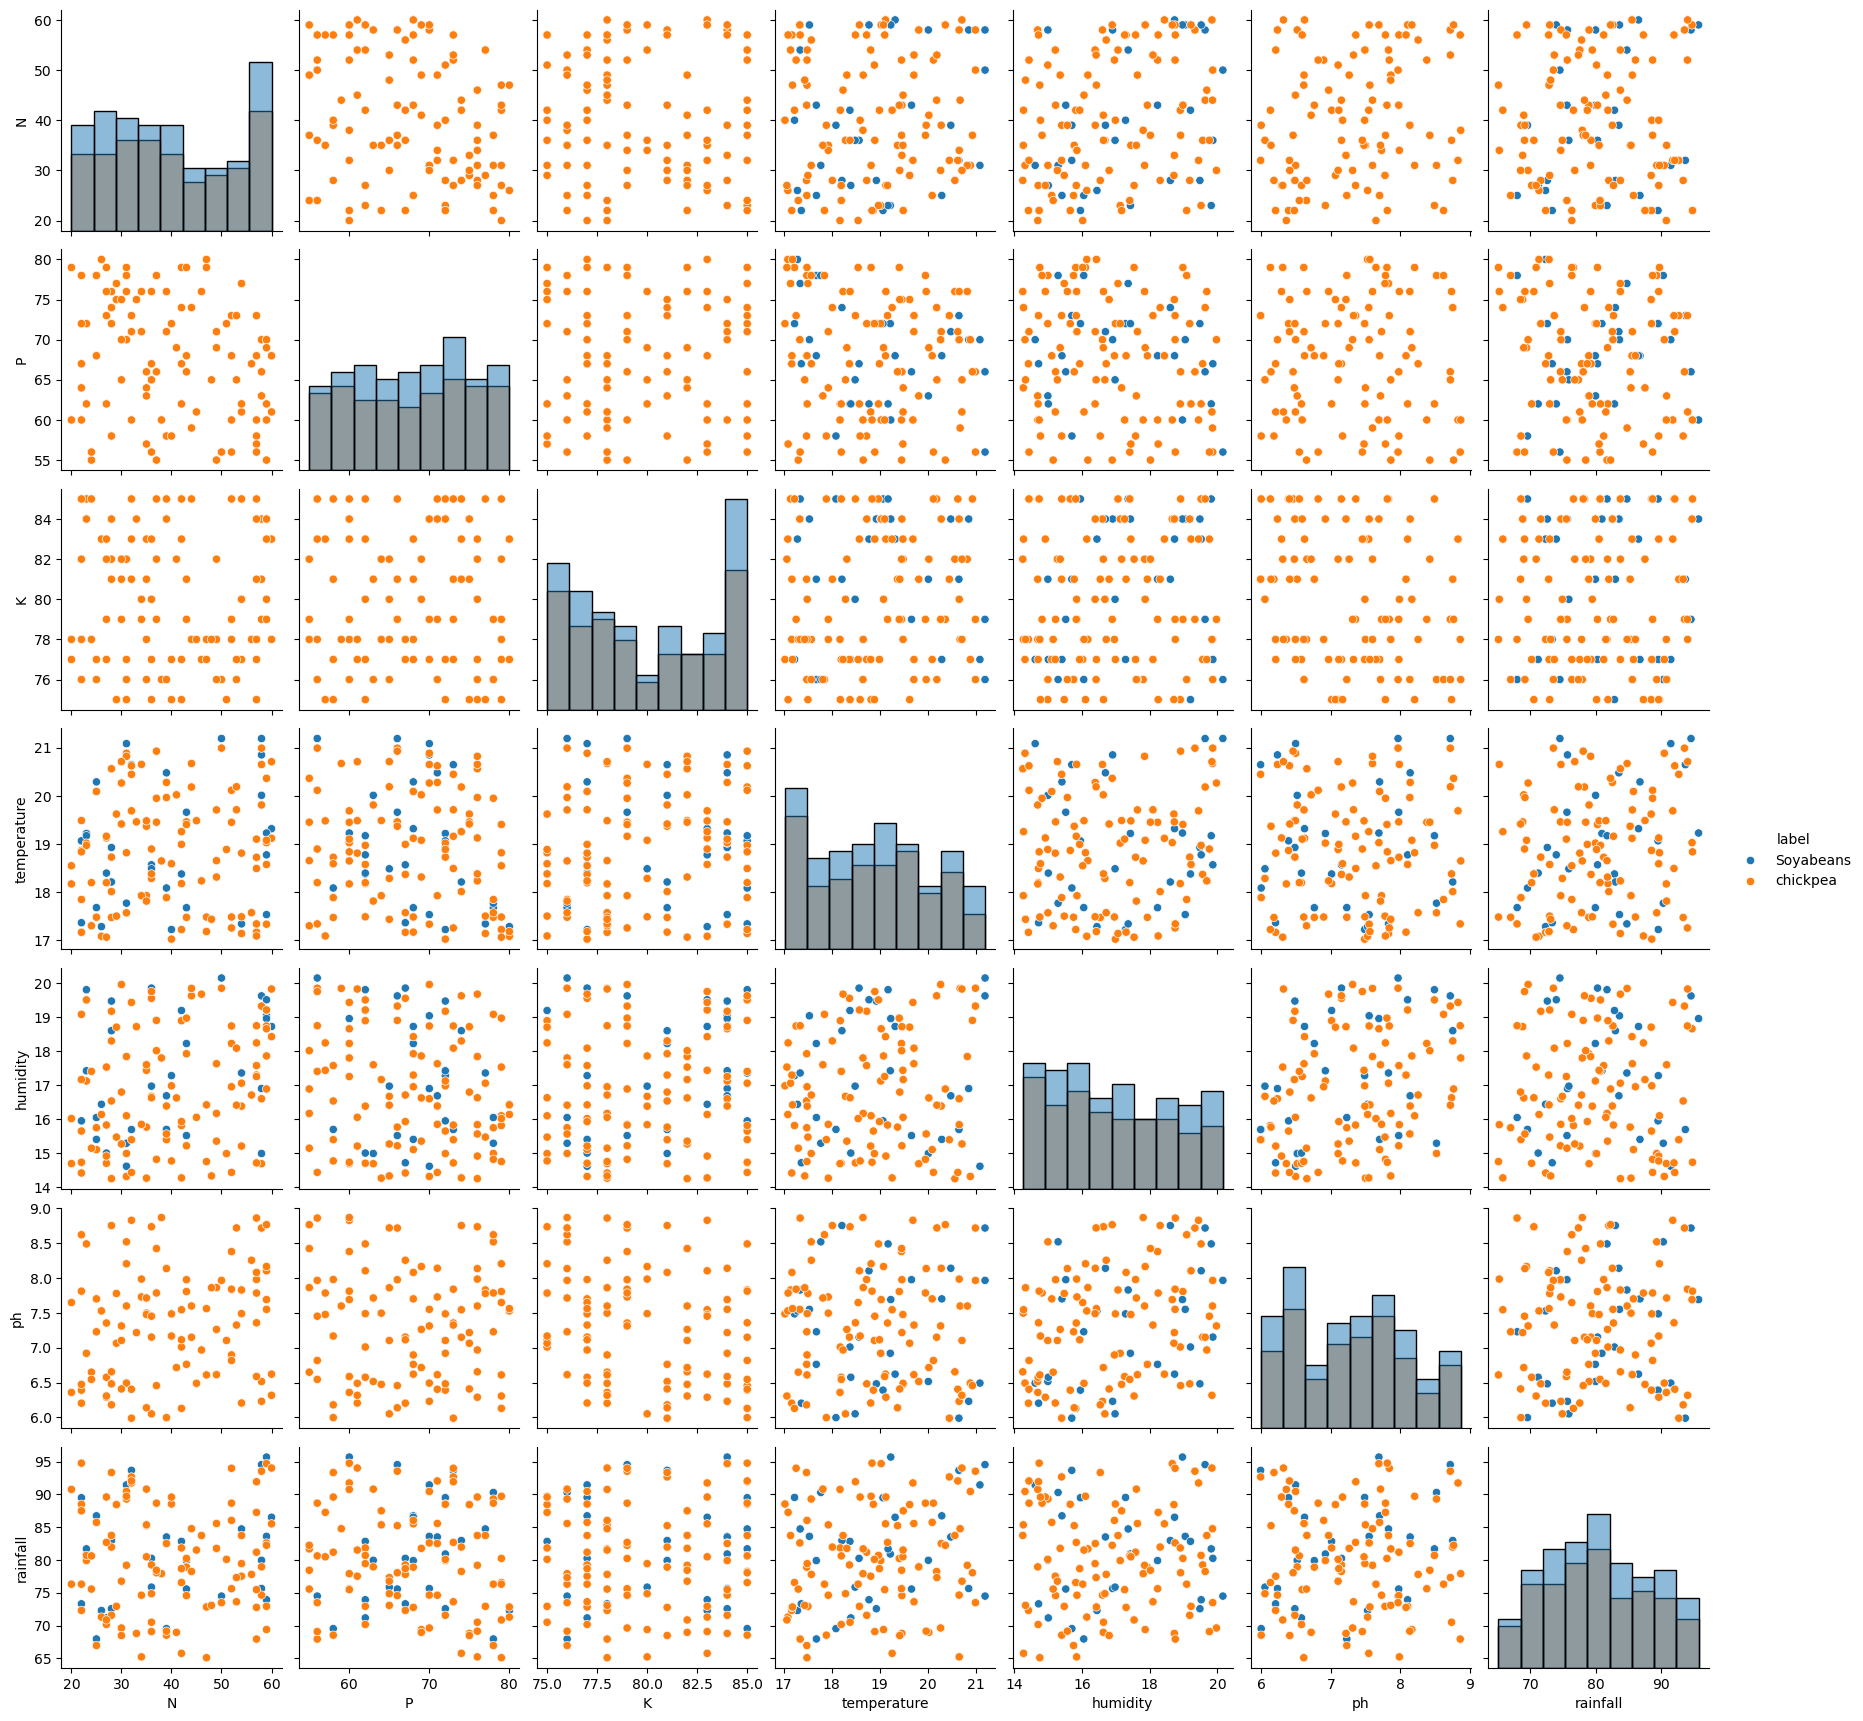

In [32]:
sns.pairplot(
    df[df['label'].isin(['chickpea', 'Soyabeans'])],
    hue='label',
    diag_kind='hist'
)

plt.show()

## 21. Checking Feature-Label Overlap

Chickpea and Soyabeans have very similar feature distributions. We check whether identical feature combinations occur with different crop labels, which could make classification difficult.

In [33]:
features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

duplicate_features = df.groupby(features)['label'].nunique()

duplicate_features[duplicate_features > 1].head(20)

N  P   K   temperature  humidity   ph        rainfall  
0  49  18  29.683617    87.935981  6.990095  41.824902     2
   55  25  28.174894    43.667230  4.524172  45.781728     2
   65  15  23.461683    23.221976  5.645436  95.842534     2
   70  21  36.300497    56.030213  4.672437  101.607399    2
1  48  24  29.345946    85.604726  6.232837  59.036300     2
   59  23  27.468530    87.176490  7.184399  43.784210     2
   66  23  19.543172    56.928314  4.803564  173.168657    2
   76  17  28.434307    52.100108  6.012719  147.041482    2
2  39  15  28.072196    82.911647  6.478557  49.618653     2
   47  15  29.868601    85.991279  6.401456  58.413941     2
   51  17  25.876823    45.963419  5.838509  38.532547     2
   56  23  26.653330    59.790234  7.550091  36.918526     2
   61  20  22.139747    23.022511  5.955617  76.641283     2
   67  18  34.519348    47.529800  5.921667  129.006461    2
3  49  18  27.910952    64.709306  3.692864  32.678919     2
   58  21  25.361405    46.82

## 22. Quantifying Conflicting Feature Combinations

Some identical feature combinations are associated with different crop labels. We calculate how many such combinations exist to understand the extent of this ambiguity in the dataset.

In [34]:
conflicting_groups = duplicate_features[duplicate_features > 1]

print("Number of conflicting feature combinations:", len(conflicting_groups))
print("Total rows involved in conflicts:",
      df.groupby(features).filter(lambda x: x['label'].nunique() > 1).shape[0])

Number of conflicting feature combinations: 354
Total rows involved in conflicts: 708


## 23. Identifying Conflicting Crop Pairs

We identify which crop labels share identical feature combinations. This helps determine which crops are inherently difficult to distinguish using the available features.

In [35]:
from itertools import combinations

conflict_df = df.groupby(features)['label'].unique()

crop_pairs = {}

for labels in conflict_df[conflict_df.apply(len) > 1]:
    for pair in combinations(sorted(labels), 2):
        crop_pairs[pair] = crop_pairs.get(pair, 0) + 1

conflict_pairs = (
    pd.DataFrame(
        crop_pairs.items(),
        columns=['Crop Pair', 'Conflicting Combinations']
    )
    .sort_values('Conflicting Combinations', ascending=False)
)

conflict_pairs.head(20)

,Crop Pair,Conflicting Combinations
1,"(groundnuts, mothbeans)",82
2,"(beans, kidneybeans)",73
4,"(Soyabeans, chickpea)",73
0,"(cowpeas, mungbean)",66
3,"(peas, pigeonpeas)",60


## 24. Random Forest Hyperparameter Tuning

Random Forest is tuned using Grid Search to determine whether a better combination of tree parameters can improve classification performance compared with the default model.

In [36]:
rf_pipeline = Pipeline([
    ("model", RandomForestClassifier(random_state=42))
])

rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5]
}

rf_grid = GridSearchCV(
    rf_pipeline,
    rf_param_grid,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best Parameters:", rf_grid.best_params_)
print("Best CV F1:", rf_grid.best_score_)

Best Parameters: {'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best CV F1: 0.7294066626289352


In [37]:
best_rf = rf_grid.best_estimator_

y_pred_rf = best_rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf, average="weighted"))
print("Recall:", recall_score(y_test, y_pred_rf, average="weighted"))
print("F1-Score:", f1_score(y_test, y_pred_rf, average="weighted"))

Accuracy: 0.7204472843450479
Precision: 0.7176999059677983
Recall: 0.7204472843450479
F1-Score: 0.7188537742535165


## 25. Logistic Regression Hyperparameter Tuning

Logistic Regression is tuned by testing different regularization strengths to determine whether its classification performance can be improved.

In [38]:
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

lr_param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

lr_grid = GridSearchCV(
    lr_pipeline,
    lr_param_grid,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1
)

lr_grid.fit(X_train, y_train)

print("Best Parameters:", lr_grid.best_params_)
print("Best CV F1:", lr_grid.best_score_)

Best Parameters: {'model__C': 100}
Best CV F1: 0.7685732922346784


In [39]:
best_lr = lr_grid.best_estimator_

y_pred_lr = best_lr.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr, average="weighted"))
print("Recall:", recall_score(y_test, y_pred_lr, average="weighted"))
print("F1-Score:", f1_score(y_test, y_pred_lr, average="weighted"))

Accuracy: 0.7667731629392971
Precision: 0.7628367854532307
Recall: 0.7667731629392971
F1-Score: 0.7629594640267696


# KNN Hyperparameter Tuning

Hyperparameter tuning was performed for the **K-Nearest Neighbors (KNN)** classifier to identify the combination of parameters that provides the best classification performance.

The following hyperparameters were evaluated:

- **Number of neighbors (`n_neighbors`)**: 3, 5, 7, 9, 11, 15, 20
- **Weighting method (`weights`)**: `uniform`, `distance`
- **Distance metric (`metric`)**: `euclidean`, `manhattan`

A **5-fold cross-validation** strategy was used, with **weighted F1-score** as the scoring metric. Since KNN is a distance-based algorithm, **StandardScaler** was applied before training.

The best combination of hyperparameters was selected based on the highest **mean cross-validation weighted F1-score**. This tuned model was then evaluated on the test set using **accuracy, precision, recall, and F1-score**.

In [40]:
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier())
])

knn_param_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 20],
    "model__weights": ["uniform", "distance"],
    "model__metric": ["euclidean", "manhattan"]
}

knn_grid = GridSearchCV(
    knn_pipeline,
    knn_param_grid,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1
)

knn_grid.fit(X_train, y_train)

print("Best Parameters:", knn_grid.best_params_)
print("Best CV F1:", knn_grid.best_score_)

Best Parameters: {'model__metric': 'manhattan', 'model__n_neighbors': 20, 'model__weights': 'uniform'}
Best CV F1: 0.7749087124043009


## 26. Evaluation of Tuned KNN

The best KNN configuration obtained through hyperparameter tuning is evaluated on the test set using accuracy, precision, recall, and F1-score.

In [41]:
best_knn = knn_grid.best_estimator_

y_pred_knn = best_knn.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print("Precision:", precision_score(y_test, y_pred_knn, average="weighted"))
print("Recall:", recall_score(y_test, y_pred_knn, average="weighted"))
print("F1-Score:", f1_score(y_test, y_pred_knn, average="weighted"))

Accuracy: 0.7827476038338658
Precision: 0.7548344338092435
Recall: 0.7827476038338658
F1-Score: 0.76319467295007


In [42]:
print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

   Soyabeans       0.57      1.00      0.72        26
       apple       1.00      1.00      1.00        27
      banana       1.00      1.00      1.00        29
       beans       0.41      0.60      0.49        20
   blackgram       0.87      1.00      0.93        20
    chickpea       0.00      0.00      0.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      0.97      0.98        29
      cotton       0.96      1.00      0.98        26
     cowpeas       0.38      0.55      0.45        20
      grapes       1.00      1.00      1.00        25
  groundnuts       0.33      0.40      0.36        20
        jute       0.83      1.00      0.91        20
 kidneybeans       0.23      0.15      0.18        20
      lentil       1.00      0.95      0.97        20
       maize       0.97      0.97      0.97        30
       mango       0.93      1.00      0.96        26
   mothbeans       0.23    

## 27. Feature Engineering

Additional ratio-based features are created from the nutrient values. These features represent the relative balance between nutrients rather than their individual values.

The engineered features are:
- N/P ratio
- N/K ratio
- P/K ratio

In [43]:
# Create nutrient ratio features
df['N_P_ratio'] = df['N'] / (df['P'] + 1)
df['N_K_ratio'] = df['N'] / (df['K'] + 1)
df['P_K_ratio'] = df['P'] / (df['K'] + 1)

df.head()

,N,P,K,temperature,humidity,ph,rainfall,label,N_P_ratio,N_K_ratio,P_K_ratio
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice,2.093023,2.045455,0.954545
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice,1.440678,2.023810,1.380952
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice,1.071429,1.333333,1.222222
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice,2.055556,1.804878,0.853659
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice,1.813953,1.813953,0.976744


In [44]:
features = [
    'N', 'P', 'K',
    'temperature', 'humidity', 'ph', 'rainfall',
    'N_P_ratio', 'N_K_ratio', 'P_K_ratio'
]

X = df[features]
y = df['label']

In [46]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [47]:
final_results = pd.DataFrame({
    "Model": [
        "SVM",
        "Logistic Regression",
        "KNN",
        "Random Forest",
        "Decision Tree"
    ],
    "Test F1": [
        0.7866,
        0.7630,
        None,
        0.7185,
        None
    ]
})

final_results.sort_values("Test F1", ascending=False)

,Model,Test F1
0,SVM,0.7866
1,Logistic Regression,0.7630
3,Random Forest,0.7185
2,KNN,NaN
4,Decision Tree,NaN


## 28. Final Model Selection

Based on test-set performance and five-fold cross-validation, SVM was selected as the final model for crop suitability classification.

The model provides the best overall performance among the evaluated classifiers. Although some crop classes remain difficult to distinguish, the model is suitable as the final baseline given the limitations of the available features.

## 29. Saving the Final Model

The selected SVM pipeline is saved using Joblib. The pipeline contains both feature scaling and the trained SVM model, making it ready for future predictions or integration with the application.

In [48]:
import joblib

# Save the final SVM pipeline
joblib.dump(best_svm, "crop_suitability_pipeline.pkl")

print("Model saved successfully!")

Model saved successfully!


In [49]:
import os

print(os.path.exists("crop_suitability_pipeline.pkl"))

True


## 30. Prediction Function

A prediction function is created to allow the trained model to predict a suitable crop from new soil and environmental conditions.

In [51]:
def predict_crop(N, P, K, temperature, humidity, ph, rainfall):
    
    input_data = pd.DataFrame([[
        N, P, K, temperature, humidity, ph, rainfall
    ]], columns=[
        'N', 'P', 'K', 'temperature',
        'humidity', 'ph', 'rainfall'
    ])
    
    prediction = best_svm.predict(input_data)
    
    return prediction[0]

In [52]:
predict_crop(
    N=90,
    P=42,
    K=43,
    temperature=20.9,
    humidity=82,
    ph=6.5,
    rainfall=202
)

'rice'

## 31. Loading and Testing the Saved Model

The saved pipeline is loaded from the `.pkl` file and tested on a new input. This confirms that the model can be reused without retraining.

In [53]:
import joblib

# Load saved pipeline
loaded_model = joblib.load("crop_suitability_pipeline.pkl")

print("Model loaded successfully!")

Model loaded successfully!


In [54]:
sample = pd.DataFrame([{
    'N': 90,
    'P': 42,
    'K': 43,
    'temperature': 20.9,
    'humidity': 82,
    'ph': 6.5,
    'rainfall': 202
}])

prediction = loaded_model.predict(sample)

print("Predicted Crop:", prediction[0])

Predicted Crop: rice
